# Instance Segmentation with Mask2Former across 3 Augmentation Strategies

All three experiments train the same **Mask2Former** (Swin-Tiny, Hugging Face Transformers) architecture on the exact same dataset, splits, and hyperparameters, varying only the training augmentation pipeline:

| # | Experiment | Augmentation level | Transforms |
|---|------------|--------------------|------------|
| 1 | **Mask2Former (No Aug)** | `no aug` | Baseline — no training augmentation (`A.Compose([])`) |
| 2 | **Mask2Former (Aug 1)** | `aug 1` | Light geometric & lighting jitter (`HorizontalFlip`, mild `Affine`, mild `RandomBrightnessContrast`) |
| 3 | **Mask2Former (Aug 2)** | `aug 2` | Heavy augmentation (`RandomResizedCrop`, `HorizontalFlip`, `VerticalFlip`, stronger `Affine`, `MotionBlur`/`GaussNoise`, `ColorJitter`, `RandomBrightnessContrast`, `HueSaturationValue`) |

```
<class_index> <x1> <y1> <x2> <y2> ... <xN> <yN>     # normalized 0..1 polygon (>= 3 points)
```

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 0. Environment

Installs only what is missing. After an install, restart the kernel and run again
(the import cells at the top must succeed).

In [2]:
import importlib.util, subprocess, sys
import contextlib, gc, io, json, math, os, random, shutil, time, warnings
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
from collections import Counter, defaultdict
from pathlib import Path

import cv2
cv2.setNumThreads(0)
cv2.ocl.setUseOpenCL(False)
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
import pandas as pd
import torch
import torch.nn as nn
import torchvision
from PIL import Image, ImageOps
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
import albumentations as A

from transformers import Mask2FormerConfig, Mask2FormerForUniversalSegmentation, Mask2FormerImageProcessor

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
import pycocotools.mask as mask_utils

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42


def seed_everything(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    # Keep cudnn.benchmark=False: Mask2Former has dynamic instance counts per batch,
    # which makes cuDNN re-autotune on almost every iteration (5-15x slowdown).
    torch.backends.cudnn.benchmark = False
    if torch.cuda.is_available():
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
        torch.set_float32_matmul_precision("high")


seed_everything()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
GPU_VRAM_GB = torch.cuda.get_device_properties(0).total_memory / 1e9 if DEVICE.type == "cuda" else 0.0
# Native bf16 Tensor Cores require Ampere+ (CC >= 8.0); T4 (CC 7.5) is faster with fp16 + GradScaler.
USE_BF16 = (
    DEVICE.type == "cuda"
    and torch.cuda.get_device_capability(0)[0] >= 8
    and torch.cuda.is_bf16_supported()
)

print(f"python      : {sys.version.split()[0]}")
print(f"torch       : {torch.__version__}")
print(f"torchvision : {torchvision.__version__}")
print(f"device      : {DEVICE}")
if DEVICE.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    cc = torch.cuda.get_device_capability(0)
    print(f"gpu         : {props.name} ({GPU_VRAM_GB:.1f} GB, CC {cc[0]}.{cc[1]})")
    amp_label = "bfloat16" if USE_BF16 else "float16"
    print(f"amp dtype   : {amp_label}")

python      : 3.13.16
torch       : 2.11.0+cu130
torchvision : 0.26.0+cu130
device      : cuda
gpu         : NVIDIA L4 (23.7 GB, CC 8.9)
amp dtype   : bfloat16


## 1. Configuration

Everything that you normally want to change lives here.

In [3]:
PROJECT_DIR = Path.cwd().resolve()

# --- input data ---------------------------------------------------------------
# A pre-split YOLO dataset folder (Roboflow / Ultralytics "seg" or "obb" export):
#   <root>/data.yaml
#   <root>/train/images  <root>/train/labels
#   <root>/valid/images  <root>/valid/labels     # "val" is accepted too
#   <root>/test/images   <root>/test/labels      # optional
# Both "valid" and "val" are accepted; "test" is optional.
DATASET_ROOT = Path("/content/panoptic-indoor-segmentation.v1-forked-v5.yolov8-obb")
if not DATASET_ROOT.is_dir():
    # Fallback to current directory check if Google Drive path is not mounted or wrong
    DATASET_ROOT = PROJECT_DIR / "panoptic-indoor-segmentation.v1-forked-v5.yolov8-obb"
if not DATASET_ROOT.is_dir():
    DATASET_ROOT = None       # None -> auto-detect a train/ folder under PROJECT_DIR

# --- dataset / preprocessing --------------------------------------------------
CLASS_NAMES = None          # e.g. ["pot", "pan", "spoon"]; None = read data.yaml / infer
IMG_SIZE = 640              # every experiment trains and is evaluated at 640x640
RESIZE_MODE = "pad"         # "pad" = letterbox (keeps aspect ratio) | "stretch"
DS_DIRNAME = "dataset_640"
EVAL_SPLIT = "val"          # "val" while iterating, "test" for the final held-out score

# --- training ----------------------------------------------------------------
FAST_DEV_RUN = False        # True: subset of images + 2 epochs, for a pipeline check
MAX_IMAGES = None           # cap the number of images per split (None = all)
import multiprocessing as _mp

M2F_CKPT = "facebook/mask2former-swin-tiny-coco-instance"

AUG_EXPERIMENTS = [
    {"key": "no_aug", "level": "no aug", "label": "Mask2Former (No Aug)"},
    {"key": "aug_1",  "level": "aug 1",  "label": "Mask2Former (Aug 1)"},
    {"key": "aug_2",  "level": "aug 2",  "label": "Mask2Former (Aug 2)"},
]

EPOCHS = {"no_aug": 50, "aug_1": 50, "aug_2": 50}
BACKBONE_LR_MULT = 0.1      # 0.1x LR on pretrained Swin-Tiny backbone
GRAD_CLIP_NORM = 0.5        # gradient norm clipping (with warmup + differential LR)
if GPU_VRAM_GB >= 12.0:
    BATCH_SIZE = 4
    LR = 2e-4
else:
    BATCH_SIZE = 4
    LR = 1e-4

# Use multi-worker prefetching on Linux fork (Colab); fall back to 0 on Windows / Python 3.14+ forkserver.
_can_fork = (
    os.name == "posix"
    and sys.version_info < (3, 14)
    and _mp.get_start_method(allow_none=True) in (None, "fork")
)
NUM_WORKERS = min(8, os.cpu_count() or 2) if _can_fork else 0

if FAST_DEV_RUN:
    MAX_IMAGES = MAX_IMAGES or 10
    EPOCHS = {k: 2 for k in EPOCHS}

OUT_DIR = PROJECT_DIR / "outputs_augmentation"
for d in (OUT_DIR,):
    d.mkdir(parents=True, exist_ok=True)

print(json.dumps({
    "project_dir": str(PROJECT_DIR), "dataset_root": str(DATASET_ROOT),
    "out_dir": str(OUT_DIR), "model_ckpt": M2F_CKPT,
    "img_size": IMG_SIZE, "resize_mode": RESIZE_MODE, "eval_split": EVAL_SPLIT,
    "fast_dev_run": FAST_DEV_RUN,
    "experiments": [e["level"] for e in AUG_EXPERIMENTS],
    "epochs": EPOCHS, "batch_size": BATCH_SIZE, "lr": LR,
    "backbone_lr_mult": BACKBONE_LR_MULT, "grad_clip_norm": GRAD_CLIP_NORM,
    "num_workers": NUM_WORKERS,
}, indent=2))

{
  "project_dir": "/content",
  "dataset_root": "/content/panoptic-indoor-segmentation.v1-forked-v5.yolov8-obb",
  "out_dir": "/content/outputs_augmentation",
  "model_ckpt": "facebook/mask2former-swin-tiny-coco-instance",
  "img_size": 640,
  "resize_mode": "pad",
  "eval_split": "val",
  "fast_dev_run": false,
  "experiments": [
    "no aug",
    "aug 1",
    "aug 2"
  ],
  "epochs": {
    "no_aug": 50,
    "aug_1": 50,
    "aug_2": 50
  },
  "batch_size": 4,
  "lr": 0.0002,
  "backbone_lr_mult": 0.1,
  "grad_clip_norm": 0.5,
  "num_workers": 8
}


## 2. Dataset Loader & Preprocessing (Self-Contained)

The input is a pre-split YOLO dataset folder (e.g., `panoptic-indoor-segmentation...yolov8-obb`):

```
<dataset_root>/
  data.yaml
  train/images    train/labels
  valid/images    valid/labels      # "val" is accepted too
  test/images     test/labels       # optional
```

Everything for discovering splits, parsing polygon/OBB/bbox labels, letterboxing to `IMG_SIZE`, writing `data.yaml` + COCO JSON annotations, and loading tensors into PyTorch (`YoloSegDataset`) is defined directly below inside the notebook (no external `.py` loader needed).

In [4]:
import yaml
from dataclasses import dataclass, field

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SPLIT_ALIASES = {"train": ("train",), "val": ("valid", "val"), "test": ("test",)}


def parse_label_line(line: str):
    parts = line.split()
    if len(parts) < 5:
        return None
    try:
        cls = int(float(parts[0]))
        vals = np.asarray([float(v) for v in parts[1:]], dtype=np.float32)
    except ValueError:
        return None
    if vals.size < 4 or vals.size % 2 != 0:
        return None
    if vals.size == 4:
        cx, cy, w, h = vals
        poly = np.array([[cx - w / 2, cy - h / 2], [cx + w / 2, cy - h / 2],
                         [cx + w / 2, cy + h / 2], [cx - w / 2, cy + h / 2]], dtype=np.float32)
        return cls, poly, "bbox"
    return cls, vals.reshape(-1, 2), "polygon"


def read_labels(path, width: int, height: int):
    if path is None or not Path(path).is_file():
        return []
    out = []
    for raw in Path(path).read_text().splitlines():
        parsed = parse_label_line(raw) if raw.strip() else None
        if parsed is None:
            continue
        cls, poly, kind = parsed
        if poly.max() > 1.5:
            poly = poly / np.array([width, height], dtype=np.float32)
        poly = np.clip(poly, 0.0, 1.0) * np.array([width, height], dtype=np.float32)
        if kind == "polygon" and cv2.contourArea(poly) < 4:
            continue
        out.append({"cls": cls, "poly": poly, "kind": kind})
    return out


def letterbox_and_scale(im: Image.Image, polys_px, size: int, mode: str = "pad", pad_value: int = 114):
    W, H = im.size
    if mode == "stretch":
        return im.resize((size, size), Image.BILINEAR), [p * np.array([size / W, size / H], np.float32) for p in polys_px]
    ratio = min(size / W, size / H)
    nw, nh = max(1, int(round(W * ratio))), max(1, int(round(H * ratio)))
    dx, dy = (size - nw) // 2, (size - nh) // 2
    out = Image.new("RGB", (size, size), (pad_value,) * 3)
    out.paste(im.resize((nw, nh), Image.BILINEAR), (dx, dy))
    return out, [p * ratio + np.array([dx, dy], np.float32) for p in polys_px]


@dataclass
class SplitPaths:
    name: str
    images_dir: Path
    labels_dir: Path | None
    image_paths: list[Path] = field(default_factory=list)
    missing_labels: list[Path] = field(default_factory=list)

    def label_for(self, image: Path) -> Path | None:
        cands = []
        if self.labels_dir is not None:
            cands.append(self.labels_dir / f"{image.stem}.txt")
        cands.append(image.with_suffix(".txt"))
        return next((c for c in cands if c.is_file()), None)


@dataclass
class DatasetSpec:
    root: Path
    splits: dict[str, SplitPaths]
    class_names: list[str]
    yaml_path: Path | None = None


@dataclass
class PreparedDataset:
    root: Path
    yaml_path: Path
    class_names: list[str]
    img_size: int
    images: dict[str, list[Path]] = field(default_factory=dict)
    labels_dirs: dict[str, Path] = field(default_factory=dict)
    coco_paths: dict[str, Path] = field(default_factory=dict)
    coco: dict[str, dict] = field(default_factory=dict)
    summary: dict[str, dict] = field(default_factory=dict)


def discover_split_dataset(root: Path | str, class_names=None) -> DatasetSpec:
    root = Path(root).resolve()
    splits = {}
    for split_name, aliases in SPLIT_ALIASES.items():
        split_dir = next((root / a for a in aliases if (root / a).is_dir()), None)
        if split_dir is None:
            continue
        img_dir = split_dir / "images" if (split_dir / "images").is_dir() else split_dir
        lbl_dir = split_dir / "labels" if (split_dir / "labels").is_dir() else None
        imgs = sorted(p for p in img_dir.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTS)
        if imgs:
            sp = SplitPaths(split_name, img_dir, lbl_dir, imgs)
            sp.missing_labels = [p for p in imgs if sp.label_for(p) is None]
            splits[split_name] = sp

    yaml_path = next((p for p in (root / "data.yaml", root / "data.yml") if p.is_file()), None)
    if class_names is None and yaml_path is not None:
        names = (yaml.safe_load(yaml_path.read_text()) or {}).get("names")
        class_names = [names[k] for k in sorted(names, key=int)] if isinstance(names, dict) else list(names or [])
    return DatasetSpec(root=root, splits=splits, class_names=list(class_names or []), yaml_path=yaml_path)


def label_statistics(spec: DatasetSpec) -> dict:
    totals, per_split, class_counts = Counter(), {}, Counter()
    for name, sp in spec.splits.items():
        c = Counter()
        for img_p in sp.image_paths:
            with Image.open(img_p) as im:
                inst = read_labels(sp.label_for(img_p), *im.size)
            c["images"] += 1
            c["empty_images"] += int(len(inst) == 0)
            c["instances"] += len(inst)
            c["polygons"] += sum(i["kind"] == "polygon" for i in inst)
            c["boxes"] += sum(i["kind"] == "bbox" for i in inst)
            class_counts.update(i["cls"] for i in inst)
        per_split[name] = dict(c)
        totals.update(c)
    return {"per_split": per_split, "overall": dict(totals), "class_counts": dict(sorted(class_counts.items()))}


def build_dataset(spec: DatasetSpec, out_root: Path | str, img_size: int = 512,
                  resize_mode: str = "pad", pad_value: int = 114, clean: bool = True) -> PreparedDataset:
    out_root = Path(out_root).resolve()
    if clean and out_root.exists():
        shutil.rmtree(out_root)
    ann_dir = out_root / "annotations"
    ann_dir.mkdir(parents=True, exist_ok=True)

    prep = PreparedDataset(out_root, out_root / "data.yaml", list(spec.class_names), img_size)
    for split_name, sp in spec.splits.items():
        img_out, lbl_out = out_root / "images" / split_name, out_root / "labels" / split_name
        img_out.mkdir(parents=True, exist_ok=True)
        lbl_out.mkdir(parents=True, exist_ok=True)

        images_meta, annotations, ann_id = [], [], 1
        for img_id, src_img in enumerate(sp.image_paths, start=1):
            with Image.open(src_img) as im:
                im = ImageOps.exif_transpose(im).convert("RGB")
            insts = read_labels(sp.label_for(src_img), *im.size)
            out_im, polys = letterbox_and_scale(im, [i["poly"] for i in insts], img_size, resize_mode, pad_value)
            dst_img = img_out / f"{src_img.stem}.jpg"
            out_im.save(dst_img, quality=95)

            yolo_lines = []
            for inst, poly in zip(insts, polys):
                norm_p = np.clip(poly / img_size, 0.0, 1.0).reshape(-1)
                if len(norm_p) >= 6 and cv2.contourArea(poly.astype(np.float32)) >= 4:
                    yolo_lines.append(" ".join([str(inst["cls"])] + [f"{v:.6f}" for v in norm_p]))
                    x1, y1 = poly.min(0)
                    x2, y2 = poly.max(0)
                    annotations.append({
                        "id": ann_id, "image_id": img_id, "category_id": int(inst["cls"]) + 1,
                        "segmentation": [poly.reshape(-1).round(2).tolist()],
                        "bbox": [float(x1), float(y1), float(max(x2 - x1, 1e-3)), float(max(y2 - y1, 1e-3))],
                        "area": float(abs(cv2.contourArea(poly.astype(np.float32)))), "iscrowd": 0,
                    })
                    ann_id += 1
            (lbl_out / f"{src_img.stem}.txt").write_text("\n".join(yolo_lines) + ("\n" if yolo_lines else ""))
            images_meta.append({"id": img_id, "file_name": dst_img.name, "width": img_size, "height": img_size})

        prep.images[split_name] = sorted(img_out.glob("*.jpg"))
        prep.labels_dirs[split_name] = lbl_out
        prep.summary[split_name] = {"images": len(images_meta), "instances": len(annotations)}
        coco_dict = {
            "info": {"description": f"{split_name} @ {img_size}px"},
            "images": images_meta, "annotations": annotations,
            "categories": [{"id": i + 1, "name": n, "supercategory": "object"} for i, n in enumerate(prep.class_names)],
        }
        coco_path = ann_dir / f"instances_{split_name}.json"
        coco_path.write_text(json.dumps(coco_dict))
        prep.coco[split_name], prep.coco_paths[split_name] = coco_dict, coco_path

    yaml_lines = [f"path: {out_root}", "train: images/train", "val: images/val"]
    if "test" in prep.summary:
        yaml_lines.append("test: images/test")
    yaml_lines += ["names:"] + [f'  {i}: "{n}"' for i, n in enumerate(prep.class_names)]
    prep.yaml_path.write_text("\n".join(yaml_lines) + "\n")
    return prep


DATA_SPEC = discover_split_dataset(DATASET_ROOT, class_names=CLASS_NAMES)
if MAX_IMAGES:
    for split in DATA_SPEC.splits.values():
        split.image_paths = split.image_paths[:MAX_IMAGES]

print(f"dataset root : {DATA_SPEC.root}")
print(f"data.yaml    : {DATA_SPEC.yaml_path or 'not found (names inferred)'}")
for name, s in DATA_SPEC.splits.items():
    rel = s.images_dir.relative_to(DATA_SPEC.root)
    print(f"  {name:<5s} {len(s.image_paths):5d} images   {rel}")
print(f"classes      : {len(DATA_SPEC.class_names)}")

dataset root : /content/panoptic-indoor-segmentation.v1-forked-v5.yolov8-obb
data.yaml    : /content/panoptic-indoor-segmentation.v1-forked-v5.yolov8-obb/data.yaml
  train   397 images   train/images
  val     166 images   valid/images
  test    359 images   test/images
classes      : 74


### 2.1 Parse labels, discover classes, check statistics

Coordinates are expected to be normalized (`0..1`). Pixel coordinates (values
`> 1.5`) are converted automatically. Polygon labels are used directly; OBB
exports (8 values = rotated rectangle corners) are treated as polygons.
Box-only lines are turned into rectangular masks, which is allowed but teaches
the network box-shaped masks - polygon labels are strongly preferred.

Class names come from `data.yaml`. Only set `CLASS_NAMES` in the config cell if
you want to override them.

In [5]:
if CLASS_NAMES is None:
    CLASS_NAMES = DATA_SPEC.class_names
NUM_CLASSES = len(CLASS_NAMES)

STATS = label_statistics(DATA_SPEC)
totals = STATS["overall"]

if totals.get("instances", 0) == 0:
    raise RuntimeError(
        "Label files were found but contain no usable instances.\n"
        "Expected lines like:  <class_idx> x1 y1 x2 y2 x3 y3 ... (normalized polygons)."
    )

print(f"{'split':<7s} {'images':>7s} {'instances':>10s} {'empty':>7s}")
for split, s in STATS["per_split"].items():
    print(f"{split:<7s} {s['images']:7d} {s['instances']:10d} {s['empty_images']:7d}")
print(f"{'total':<7s} {totals['images']:7d} {totals['instances']:10d} {totals['empty_images']:7d}")
print(f"label types      : polygons={totals['polygons']}, boxes={totals['boxes']}")
print(f"classes          : {NUM_CLASSES}")

class_counts = Counter(STATS["class_counts"])
for i, name in enumerate(CLASS_NAMES):
    print(f"  {i:2d} {name:<24s} {class_counts.get(i, 0):5d} instances")

if totals["boxes"]:
    print("\nNOTE: box-only labels become rectangular masks. Prefer polygon annotations.")

split    images  instances   empty
train       397       4479       0
val         166       2022       1
test        359       5344       0
total       922      11845       1
label types      : polygons=11845, boxes=0
classes          : 74
   0 backpack                    36 instances
   1 bed                        103 instances
   2 blanket                     38 instances
   3 book                       469 instances
   4 bottle                     130 instances
   5 bowl                       181 instances
   6 box                        181 instances
   7 cabinet-merged             176 instances
   8 cardboard                   16 instances
   9 ceiling-merged             254 instances
  10 cell phone                  53 instances
  11 chair                      637 instances
  12 clock                        7 instances
  13 couch                      101 instances
  14 counter                    227 instances
  15 cup                        203 instances
  16 curtain            

## 3. Preprocessing: EXIF fix, 640 px letterbox, keep the existing splits

Two things matter here and are easy to get wrong:

1. **EXIF orientation.** Phone photos often carry an EXIF rotation flag. If the
   annotation tool showed them upright, the pixel array must be rotated the same way
   before resizing (`ImageOps.exif_transpose` does exactly that). Without this, about
   half of the masks would be rotated 90 degrees relative to the image.
2. **Aspect ratio.** `RESIZE_MODE="pad"` letterboxes to a square 640 canvas (grey 114
   padding). Polygon coordinates are transformed with the same scale/offset, so masks
   stay aligned. `"stretch"` compresses directly.

`build_dataset()` processes every split found in the input folder and writes the result
to `dataset_640/`. The train/valid/test division is preserved; `test` is only built when
the input folder has one.

The generated `dataset_640/` folder is the single source of truth for all three
augmentation experiments: *both* the normalized polygon txt labels and the COCO json
annotations are derived from it.

In [6]:
DS_ROOT = PROJECT_DIR / DS_DIRNAME
PAD_VALUE = 114

PREPARED = build_dataset(
    DATA_SPEC,
    DS_ROOT,
    img_size=IMG_SIZE,
    resize_mode=RESIZE_MODE,
    pad_value=PAD_VALUE,
    clean=True,
)

DATA_YAML = PREPARED.yaml_path
TRAIN_IMAGES = PREPARED.images["train"]
VAL_IMAGES = PREPARED.images["val"]
TEST_IMAGES = PREPARED.images.get("test", [])
TRAIN_LABELS = PREPARED.labels_dirs["train"]
VAL_LABELS = PREPARED.labels_dirs["val"]
TEST_LABELS = PREPARED.labels_dirs.get("test")

EVAL_SPLIT = EVAL_SPLIT if EVAL_SPLIT in PREPARED.images else "val"
EVAL_IMAGES = PREPARED.images[EVAL_SPLIT]
EVAL_COCO = PREPARED.coco_paths[EVAL_SPLIT]
EVAL_LABELS = PREPARED.labels_dirs[EVAL_SPLIT]

print(json.dumps(PREPARED.summary, indent=2))
print(f"\ndataset : {DS_ROOT}")
print(f"yaml    : {DATA_YAML.read_text()}")
print(f"train/val/test images : {len(TRAIN_IMAGES)} / {len(VAL_IMAGES)} / {len(TEST_IMAGES)}")
print(f"evaluation split      : {EVAL_SPLIT} ({len(EVAL_IMAGES)} images)")

{
  "train": {
    "images": 397,
    "instances": 4479
  },
  "val": {
    "images": 166,
    "instances": 2022
  },
  "test": {
    "images": 359,
    "instances": 5344
  }
}

dataset : /content/dataset_640
yaml    : path: /content/dataset_640
train: images/train
val: images/val
test: images/test
names:
  0: "backpack"
  1: "bed"
  2: "blanket"
  3: "book"
  4: "bottle"
  5: "bowl"
  6: "box"
  7: "cabinet-merged"
  8: "cardboard"
  9: "ceiling-merged"
  10: "cell phone"
  11: "chair"
  12: "clock"
  13: "couch"
  14: "counter"
  15: "cup"
  16: "curtain"
  17: "dining table"
  18: "door-stuff"
  19: "fire-extinguisher"
  20: "floor-other-merged"
  21: "floor-wood"
  22: "flower"
  23: "food-other-merged"
  24: "fork"
  25: "hair drier"
  26: "handbag"
  27: "keyboard"
  28: "knife"
  29: "laptop"
  30: "light"
  31: "microwave"
  32: "mirror-stuff"
  33: "mouse"
  34: "oven"
  35: "pan"
  36: "paper"
  37: "paper-merged"
  38: "person"
  39: "pillow"
  40: "plate"
  41: "plug"
  42:

### 3.1 COCO json (polygons in pixels)

`pycocotools` gives us a single, trustworthy mAP implementation across all three
augmentation runs. Category ids are `yolo_class_index + 1`.

In [7]:
coco_train = PREPARED.coco["train"]
coco_val = PREPARED.coco["val"]
coco_test = PREPARED.coco.get("test")

COCO_TRAIN = PREPARED.coco_paths["train"]
COCO_VAL = PREPARED.coco_paths["val"]
COCO_TEST = PREPARED.coco_paths.get("test")

for split, coco in (("train", coco_train), ("val", coco_val), ("test", coco_test)):
    if coco is None:
        continue
    print(f"{split:<5s}: {len(coco['images'])} images / {len(coco['annotations'])} instances")
print(f"cats : {[(c['id'], c['name']) for c in coco_train['categories']]}")
print(f"json : {COCO_TRAIN.parent}")

train: 397 images / 4479 instances
val  : 166 images / 2022 instances
test : 359 images / 5344 instances
cats : [(1, 'backpack'), (2, 'bed'), (3, 'blanket'), (4, 'book'), (5, 'bottle'), (6, 'bowl'), (7, 'box'), (8, 'cabinet-merged'), (9, 'cardboard'), (10, 'ceiling-merged'), (11, 'cell phone'), (12, 'chair'), (13, 'clock'), (14, 'couch'), (15, 'counter'), (16, 'cup'), (17, 'curtain'), (18, 'dining table'), (19, 'door-stuff'), (20, 'fire-extinguisher'), (21, 'floor-other-merged'), (22, 'floor-wood'), (23, 'flower'), (24, 'food-other-merged'), (25, 'fork'), (26, 'hair drier'), (27, 'handbag'), (28, 'keyboard'), (29, 'knife'), (30, 'laptop'), (31, 'light'), (32, 'microwave'), (33, 'mirror-stuff'), (34, 'mouse'), (35, 'oven'), (36, 'pan'), (37, 'paper'), (38, 'paper-merged'), (39, 'person'), (40, 'pillow'), (41, 'plate'), (42, 'plug'), (43, 'potted plant'), (44, 'refrigerator'), (45, 'remote'), (46, 'rug-merged'), (47, 'scissor'), (48, 'scissors'), (49, 'shelf'), (50, 'sink'), (51, 'spoon'

### 3.2 Sanity check: look at the ground truth

Masked regions are drawn from the polygons that Mask2Former will actually see.

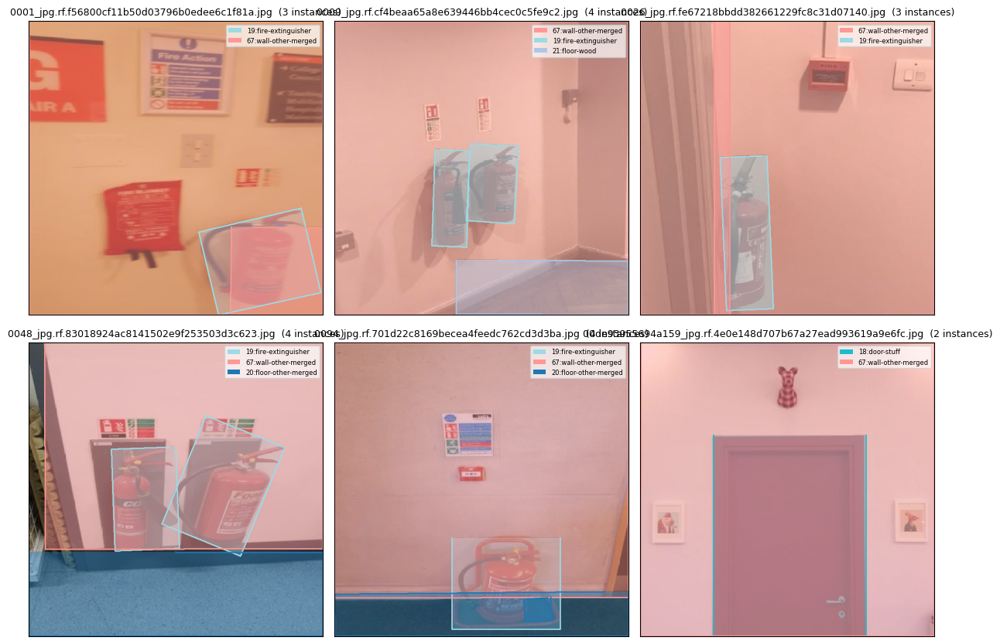

In [8]:
PALETTE = np.array(plt.get_cmap("tab20").colors)


def draw_instances(ax, image, masks, labels, scores=None, alpha=0.45, title=None, legend=True):
    ax.imshow(image)
    ax.set_xticks([]); ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=9)
    seen = []
    for i, (m, lab) in enumerate(zip(masks, labels)):
        m = np.asarray(m) > 0
        if m.sum() == 0:
            continue
        color = PALETTE[int(lab) % len(PALETTE)]
        overlay = np.zeros((*m.shape, 4), np.float32)
        overlay[m] = (*color[:3], alpha)
        ax.imshow(overlay)
        cnts, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        for c in cnts:
            ax.plot(c[:, 0, 0], c[:, 0, 1], color=color, lw=1.2)
        seen.append(int(lab))
    if legend and seen:
        handles = [Patch(facecolor=PALETTE[l % len(PALETTE)], label=f"{l}:{CLASS_NAMES[l]}")
                   for l in dict.fromkeys(seen) if l < len(CLASS_NAMES)]
        ax.legend(handles=handles, loc="upper right", fontsize=6, framealpha=0.7)


def load_rgb(path):
    with Image.open(path) as im:
        return np.asarray(ImageOps.exif_transpose(im).convert("RGB"))


def masks_from_instances(instances, S=IMG_SIZE):
    masks, labels = [], []
    for inst in instances:
        m = np.zeros((S, S), np.uint8)
        cv2.fillPoly(m, [np.round(inst["poly"]).astype(np.int32)], 1)
        if m.any():
            masks.append(m)
            labels.append(inst["cls"])
    return masks, labels


show = sorted((DS_ROOT / "images" / "train").glob("*.jpg"))[:6]
fig, axes = plt.subplots(2, 3, figsize=(12, 8.6))
for ax, p in zip(axes.ravel(), show):
    masks, labels = masks_from_instances(read_labels(TRAIN_LABELS / f"{p.stem}.txt", IMG_SIZE, IMG_SIZE))
    draw_instances(ax, load_rgb(p), masks, labels, title=f"{p.name}  ({len(masks)} instances)")
for ax in axes.ravel()[len(show):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Augmentation Strategies (No Aug vs. Aug 1 vs. Aug 2)

Three Albumentations pipelines, applied on the fly inside `Dataset.__getitem__`
(nothing is written to disk):

| level | transforms | purpose |
|-------|------------|---------|
| `no aug` | `A.Compose([])` | Clean baseline with zero training augmentation |
| `aug 1` | `HorizontalFlip(p=0.5)`, `Affine(scale 0.95-1.05, translate +-2%, rotate +-5, p=0.3)`, `RandomBrightnessContrast(0.1/0.1, p=0.5)` | Mild geometric & lighting jitter |
| `aug 2` | `RandomResizedCrop(scale 0.6-1.0)`, `HorizontalFlip(0.5)`, `VerticalFlip(0.2)`, `Affine(scale 0.9-1.1, translate +-5%, rotate +-12, p=0.5)`, `OneOf([MotionBlur, GaussNoise], p=0.2)`, `ColorJitter(0.3/0.3/0.3/0.05, p=0.8)`, `RandomBrightnessContrast(0.3)`, `HueSaturationValue(0.2)` | Heavy scale, geometric, noise, and color augmentation |

Each pipeline transforms **masks directly** (no `bbox_params`), so masks and labels can
never get out of sync. Instances that are cropped away or shrink below 8 px are removed
by the dataset's area check.

In [9]:
MEAN = np.array([0.485, 0.456, 0.406], np.float32)
STD = np.array([0.229, 0.224, 0.225], np.float32)
print("albumentations", A.__version__)


def build_train_transform(level="aug 2", S: int = IMG_SIZE):
    # Masks are the source of truth: no bbox_params here. Albumentations filters
    # bboxes (and label_fields) independently of `masks`, which can leave the two
    # lists with different lengths. Labels/masks therefore stay in sync.

    if level == "no aug":
        return A.Compose([])
    elif level == "aug 1":
        return A.Compose([
            A.HorizontalFlip(p=0.5),
            A.Affine(scale=(0.95, 1.05), translate_percent=(-0.02, 0.02), rotate=(-5, 5),
                     border_mode=cv2.BORDER_CONSTANT, fill=PAD_VALUE, fill_mask=0, p=0.3),
            A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.5),
        ])
    elif level == "aug 2":
        return A.Compose([
            A.RandomResizedCrop(size=(S, S), scale=(0.6, 1.0), ratio=(0.75, 1.33), p=1.0),
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.2),
            A.Affine(scale=(0.9, 1.1), translate_percent=(-0.05, 0.05), rotate=(-12, 12),
                     border_mode=cv2.BORDER_CONSTANT, fill=PAD_VALUE, fill_mask=0, p=0.5),
            A.OneOf([A.MotionBlur(blur_limit=3, p=1.0), A.GaussNoise(p=1.0)], p=0.2),
            A.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05, p=0.8),
            A.RandomBrightnessContrast(p=0.3),
            A.HueSaturationValue(p=0.2),
        ])
    else:
        raise ValueError(f"Unknown augmentation level: {level!r}")


TRAIN_TFS = {exp["key"]: build_train_transform(exp["level"]) for exp in AUG_EXPERIMENTS}
for exp in AUG_EXPERIMENTS:
    print(f"\n--- {exp['label']} ({exp['level']}) ---")
    print(TRAIN_TFS[exp["key"]])

albumentations 2.0.8

--- Mask2Former (No Aug) (no aug) ---
Compose([
], p=1.0, bbox_params=None, keypoint_params=None, additional_targets={}, is_check_shapes=True)

--- Mask2Former (Aug 1) (aug 1) ---
Compose([
  HorizontalFlip(p=0.5),
  Affine(p=0.3, balanced_scale=False, border_mode=0, fill=114.0, fill_mask=0.0, fit_output=False, interpolation=1, keep_ratio=False, mask_interpolation=0, rotate=(-5.0, 5.0), rotate_method='largest_box', scale={'x': (0.95, 1.05), 'y': (0.95, 1.05)}, shear={'x': (0.0, 0.0), 'y': (0.0, 0.0)}, translate_percent={'x': (-0.02, 0.02), 'y': (-0.02, 0.02)}, translate_px=None),
  RandomBrightnessContrast(p=0.5, brightness_by_max=True, brightness_limit=(-0.1, 0.1), contrast_limit=(-0.1, 0.1), ensure_safe_range=False),
], p=1.0, bbox_params=None, keypoint_params=None, additional_targets={}, is_check_shapes=True)

--- Mask2Former (Aug 2) (aug 2) ---
Compose([
  RandomResizedCrop(p=1.0, area_for_downscale=None, interpolation=1, mask_interpolation=0, ratio=(0.75, 1.3

## 5. Shared PyTorch & Mask2Former Plumbing

`YoloSegDataset(..., as_hf=True)` yields `{pixel_values, mask_labels, class_labels}`
(0-based labels, one binary mask per instance, ImageNet mean/std normalized), which is
directly consumed by `Mask2FormerForUniversalSegmentation`.

All three experiments share the exact same model initialization, optimizer (`AdamW`),
cosine learning-rate schedule, validation set, and evaluation pipeline.

In [10]:
class YoloSegDataset(Dataset):
    """Simple in-notebook PyTorch Dataset for Hugging Face Mask2Former."""

    def __init__(self, images, labels_dir, transform=None, S=IMG_SIZE, as_hf=True, label_offset=1, cache_ram=True):
        self.images = [Path(p) for p in images]
        self.labels_dir = Path(labels_dir)
        self.transform = transform
        self.S = S
        self.as_hf = as_hf
        self.label_offset = label_offset
        self._mean_t = torch.from_numpy(MEAN)[:, None, None]
        self._std_t = torch.from_numpy(STD)[:, None, None]
        # Cache only compact uint8 RGB images + parsed polygons (~0.5 GB at 640px) instead of
        # pre-rasterized 640x640 masks / float32 tensors (~6-8 GB peak, which triggers Colab RAM OOM).
        self._cache = None
        if cache_ram:
            self._cache = [
                (load_rgb(p), read_labels(self.labels_dir / f"{p.stem}.txt", self.S, self.S))
                for p in self.images
            ]

    def _rasterize(self, insts):
        masks_list, labels_list = [], []
        for inst in insts:
            m = np.zeros((self.S, self.S), np.uint8)
            cv2.fillPoly(m, [np.round(inst["poly"]).astype(np.int32)], 1)
            if m.any():
                masks_list.append(m)
                labels_list.append(inst["cls"] + self.label_offset)
        return masks_list, labels_list

    def _pack(self, idx, img, masks_list, labels_list):
        # Filter out masks that became too small (< 8 px) after augmentation
        valid = []
        for m, lbl in zip(masks_list, labels_list):
            area = int(m.sum())
            if area >= 8:
                valid.append((m, lbl, float(area)))

        if valid:
            masks = np.stack([v[0] for v in valid])
            labels = np.array([v[1] for v in valid], dtype=np.int64)
            areas = np.array([v[2] for v in valid], dtype=np.float32)
        else:
            masks = np.zeros((0, self.S, self.S), dtype=np.uint8)
            labels = np.zeros(0, dtype=np.int64)
            areas = np.zeros(0, dtype=np.float32)

        x = torch.from_numpy(np.ascontiguousarray(img)).permute(2, 0, 1).float().div_(255.0)
        x = (x - self._mean_t) / self._std_t

        if self.as_hf:
            # Keep mask_labels as uint8 [K, H, W] on CPU (4x less RAM/IPC); cast to float32 on GPU.
            return {
                "pixel_values": x,
                "mask_labels": torch.from_numpy(masks),
                "class_labels": torch.from_numpy(labels - self.label_offset),
            }

        boxes = [polygon_bbox_from_mask(m) for m in masks]
        return x, {
            "boxes": torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4),
            "labels": torch.from_numpy(labels),
            "masks": torch.from_numpy(masks),
            "image_id": torch.tensor([idx]),
            "area": torch.tensor(areas, dtype=torch.float32),
            "iscrowd": torch.zeros(len(masks), dtype=torch.int64),
        }

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        if self._cache is not None:
            img, insts = self._cache[idx]
            img = img.copy()
        else:
            p = self.images[idx]
            img = load_rgb(p)
            insts = read_labels(self.labels_dir / f"{p.stem}.txt", self.S, self.S)

        masks_list, labels_list = self._rasterize(insts)

        if self.transform is not None and masks_list:
            out = self.transform(image=img, masks=masks_list)
            img, masks_list = out["image"], out["masks"]
        elif self.transform is not None:
            img = self.transform(image=img)["image"]

        return self._pack(idx, img, masks_list, labels_list)


def polygon_bbox_from_mask(mask):
    rows = np.flatnonzero(mask.any(axis=1))
    if rows.size == 0:
        return [0.0, 0.0, 1.0, 1.0]
    cols = np.flatnonzero(mask.any(axis=0))
    return [float(cols[0]), float(rows[0]), float(cols[-1] + 1), float(rows[-1] + 1)]


def dataloader_worker_init(_worker_id):
    cv2.setNumThreads(0)
    cv2.ocl.setUseOpenCL(False)


def hf_collate(batch):
    return {
        "pixel_values": torch.stack([b["pixel_values"] for b in batch]),
        "mask_labels": [b["mask_labels"] for b in batch],
        "class_labels": [b["class_labels"] for b in batch],
    }


def amp_ctx():
    if not USE_AMP:
        return contextlib.nullcontext()
    dtype = torch.bfloat16 if USE_BF16 else torch.float16
    return torch.autocast("cuda", dtype=dtype)


_dl_extra = (
    {"persistent_workers": True, "prefetch_factor": 2, "worker_init_fn": dataloader_worker_init}
    if NUM_WORKERS > 0
    else {}
)

print("In-notebook Mask2Former dataset loader ready")

In-notebook Mask2Former dataset loader ready


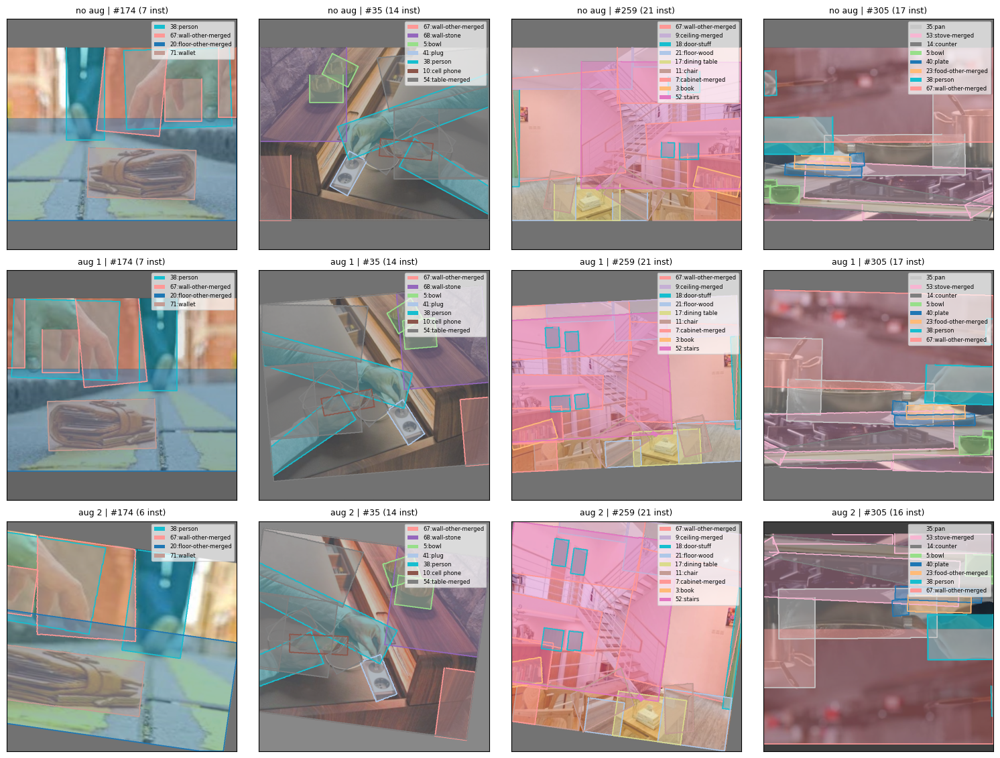

In [11]:
# Side-by-side preview of the 3 augmentation levels on the same training images
n_preview = min(4, len(TRAIN_IMAGES))
idxs = np.random.default_rng(SEED).choice(len(TRAIN_IMAGES), size=n_preview, replace=False)

fig, axes = plt.subplots(len(AUG_EXPERIMENTS), n_preview, figsize=(3.8 * n_preview, 3.8 * len(AUG_EXPERIMENTS)))
if n_preview == 1:
    axes = axes[:, None]

for row, exp in enumerate(AUG_EXPERIMENTS):
    ds_prev = YoloSegDataset(TRAIN_IMAGES, TRAIN_LABELS, transform=TRAIN_TFS[exp["key"]], as_hf=True, cache_ram=False)
    for col, idx in enumerate(idxs):
        sample = ds_prev[int(idx)]
        img = (sample["pixel_values"].permute(1, 2, 0).numpy() * STD + MEAN).clip(0, 1)
        masks = sample["mask_labels"].numpy()
        labels = sample["class_labels"].numpy()
        draw_instances(
            axes[row, col], img, masks, labels,
            title=f"{exp['level']} | #{int(idx)} ({len(labels)} inst)",
        )
    del ds_prev

plt.tight_layout()
plt.savefig(OUT_DIR / "augmentation_preview.png", dpi=140)
plt.show()

In [12]:
# Shared Mask2Former processor, validation loader, training loop, and prediction helpers
m2f_processor = Mask2FormerImageProcessor(
    size={"height": IMG_SIZE, "width": IMG_SIZE}, ignore_index=255, reduce_labels=False
)

hf_val_ds = YoloSegDataset(VAL_IMAGES, VAL_LABELS, transform=None, as_hf=True)
hf_val_loader = DataLoader(
    hf_val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, collate_fn=hf_collate, pin_memory=USE_AMP,
    **_dl_extra,
)

demo = VAL_IMAGES[:3]
M2F_DIRS = {exp["key"]: OUT_DIR / f"mask2former_{exp['key']}" for exp in AUG_EXPERIMENTS}
M2F_HISTORIES = {}


def build_mask2former():
    m2f_config = Mask2FormerConfig.from_pretrained(M2F_CKPT)
    m2f_config.num_labels = NUM_CLASSES
    m2f_config.use_auxiliary_loss = True
    model = Mask2FormerForUniversalSegmentation.from_pretrained(
        M2F_CKPT, config=m2f_config, ignore_mismatched_sizes=True
    ).to(DEVICE)
    return model


@torch.no_grad()
def mask2former_val_loss(model, loader):
    model.eval()
    total, n = torch.zeros((), device=DEVICE), 0
    for batch in loader:
        pv = batch["pixel_values"].to(DEVICE, non_blocking=USE_AMP)
        ml = [m.to(DEVICE, non_blocking=USE_AMP, dtype=torch.float32) for m in batch["mask_labels"]]
        cl = [c.to(DEVICE, non_blocking=USE_AMP) for c in batch["class_labels"]]
        if sum(len(c) for c in cl) == 0:
            continue
        with amp_ctx():
            loss = model(pixel_values=pv, mask_labels=ml, class_labels=cl).loss
        total = total + loss.detach().float()
        n += 1
    return float(total.item()) / max(n, 1)


def train_mask2former_experiment(exp_key: str, run_label: str):
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    # Reset RNG before each experiment so model init and batch ordering are fair & reproducible
    seed_everything(SEED)

    run_dir = M2F_DIRS[exp_key]
    run_dir.mkdir(parents=True, exist_ok=True)
    n_epochs = EPOCHS[exp_key]

    model = build_mask2former()
    print(f"[{run_label}] Mask2Former params: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} M")
    print(f"[{run_label}] num_labels: {model.config.num_labels} | queries: {model.config.num_queries}")

    hf_train_ds = YoloSegDataset(TRAIN_IMAGES, TRAIN_LABELS, transform=TRAIN_TFS[exp_key], as_hf=True)
    hf_train_loader = DataLoader(
        hf_train_ds, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=NUM_WORKERS, collate_fn=hf_collate, pin_memory=USE_AMP,
        **_dl_extra,
    )

    batch = next(iter(hf_train_loader))
    print(f"[{run_label}] sample batch:", {
        k: (tuple(v.shape) if torch.is_tensor(v) else f"list[{len(v)}] of {tuple(v[0].shape)}")
        for k, v in batch.items()
    })
    del batch

    backbone_params, head_params = [], []
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if "pixel_level_module.encoder" in name:
            backbone_params.append(p)
        else:
            head_params.append(p)
    params = backbone_params + head_params

    opt = torch.optim.AdamW(
        [
            {"params": backbone_params, "lr": LR * BACKBONE_LR_MULT},
            {"params": head_params, "lr": LR},
        ],
        weight_decay=0.05,
        fused=(DEVICE.type == "cuda"),
    )
    warmup_epochs = min(5, max(1, n_epochs // 10))
    if n_epochs > warmup_epochs:
        warmup_sched = torch.optim.lr_scheduler.LinearLR(
            opt, start_factor=0.1, end_factor=1.0, total_iters=warmup_epochs
        )
        cosine_sched = torch.optim.lr_scheduler.CosineAnnealingLR(
            opt, T_max=n_epochs - warmup_epochs
        )
        sched = torch.optim.lr_scheduler.SequentialLR(
            opt, schedulers=[warmup_sched, cosine_sched], milestones=[warmup_epochs]
        )
    else:
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(1, n_epochs))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and not USE_BF16)

    history, best_val = [], float("inf")
    for epoch in range(n_epochs):
        model.train()
        running, seen = torch.zeros((), device=DEVICE), 0
        pbar = tqdm(hf_train_loader, desc=f"{run_label} {epoch + 1}/{n_epochs}", leave=False)
        for batch in pbar:
            pv = batch["pixel_values"].to(DEVICE, non_blocking=USE_AMP)
            ml = [m.to(DEVICE, non_blocking=USE_AMP, dtype=torch.float32) for m in batch["mask_labels"]]
            cl = [c.to(DEVICE, non_blocking=USE_AMP) for c in batch["class_labels"]]
            if sum(len(c) for c in cl) == 0:      # nothing to match against
                continue

            with amp_ctx():
                loss = model(pixel_values=pv, mask_labels=ml, class_labels=cl).loss
            opt.zero_grad(set_to_none=True)
            if scaler.is_enabled():
                scaler.scale(loss).backward()
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(params, GRAD_CLIP_NORM)
                scaler.step(opt)
                scaler.update()
            else:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(params, GRAD_CLIP_NORM)
                opt.step()

            running = running + loss.detach().float()
            seen += 1
            if seen % 5 == 0 or seen == len(hf_train_loader):
                pbar.set_postfix(loss=f"{loss.detach().item():.3f}")

        train_epoch_loss = float(running.item()) / max(seen, 1)
        val = mask2former_val_loss(model, hf_val_loader)
        sched.step()
        lr_backbone = opt.param_groups[0]["lr"]
        lr_head = opt.param_groups[1]["lr"]
        history.append({
            "epoch": epoch + 1,
            "train_loss": train_epoch_loss,
            "val_loss": val,
            "lr": lr_head,
            "lr_backbone": lr_backbone,
        })
        if val < best_val:
            best_val = val
            model.save_pretrained(run_dir)
            m2f_processor.save_pretrained(run_dir)
        print(f"epoch {epoch + 1:02d} | train {train_epoch_loss:.3f} | val {val:.3f} | "
              f"lr {lr_head:.2e} (bb {lr_backbone:.2e})")

    # keep the last state and history too
    model.save_pretrained(run_dir / "last")
    (run_dir / "history.json").write_text(json.dumps(history, indent=2))
    print("saved:", run_dir)

    # Free training VRAM & DataLoader workers before the next experiment
    model.cpu()
    del model, opt, sched, scaler, params, backbone_params, head_params, hf_train_loader, hf_train_ds
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    M2F_HISTORIES[exp_key] = history
    return history, run_dir


def load_best_mask2former(run_dir: Path):
    ckpt_dir = run_dir if (run_dir / "config.json").exists() else (run_dir / "last")
    return Mask2FormerForUniversalSegmentation.from_pretrained(ckpt_dir).to(DEVICE).eval()


@torch.no_grad()
def mask2former_predict(model, processor, image_paths, score_thr=0.5, max_det=50, batch_size=None):
    """Uniform prediction format: list of {masks, labels(0-based), scores}.
    Uses return_binary_maps=True so high-index queries do not overwrite earlier queries
    on a single 2D canvas when score_thr is low during mAP evaluation.
    """
    model.to(DEVICE).eval()
    bs = batch_size or BATCH_SIZE
    t_mean, t_std = torch.from_numpy(MEAN)[:, None, None], torch.from_numpy(STD)[:, None, None]
    out = []
    for i in range(0, len(image_paths), bs):
        xs = []
        for p in image_paths[i:i + bs]:
            x = torch.from_numpy(np.ascontiguousarray(load_rgb(p))).permute(2, 0, 1).float().div(255.0)
            xs.append((x - t_mean) / t_std)
        pv = torch.stack(xs).to(DEVICE, non_blocking=USE_AMP)
        with amp_ctx():
            outputs = model(pixel_values=pv)
        proc = processor.post_process_instance_segmentation(
            outputs, threshold=score_thr, mask_threshold=0.5,
            overlap_mask_area_threshold=0.8,
            target_sizes=[(IMG_SIZE, IMG_SIZE)] * len(xs),
            return_binary_maps=True,
        )
        for d in proc:
            seg = d["segmentation"]
            infos = d["segments_info"][:max_det]
            if seg is None or len(infos) == 0:
                out.append({"masks": np.zeros((0, IMG_SIZE, IMG_SIZE), bool),
                            "labels": np.zeros(0, np.int64), "scores": np.zeros(0, np.float32)})
                continue
            masks = (seg[:len(infos)] > 0.5).cpu().numpy()
            labels = np.array([int(info.get("category_id", info.get("label_id"))) for info in infos], np.int64)
            scores = np.array([float(info["score"]) for info in infos], np.float32)
            out.append({"masks": masks, "labels": labels, "scores": scores})
    return out


def plot_m2f_history(history, title: str):
    df = pd.DataFrame(history)
    ax = df.set_index("epoch")[["train_loss", "val_loss"]].plot(
        figsize=(8, 4), marker="o", title=title
    )
    ax.set_ylabel("loss")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    return df.tail().round(4)


def preview_m2f_run(run_dir: Path, title: str):
    model_eval = load_best_mask2former(run_dir)
    preds = mask2former_predict(model_eval, m2f_processor, demo, score_thr=0.5, max_det=50)
    fig, axes = plt.subplots(2, len(demo), figsize=(4.2 * len(demo), 8.6))
    if len(demo) == 1:
        axes = axes[:, None]
    for j, (p, pred) in enumerate(zip(demo, preds)):
        gt_m, gt_l = masks_from_instances(read_labels(VAL_LABELS / f"{p.stem}.txt", IMG_SIZE, IMG_SIZE))
        draw_instances(axes[0, j], load_rgb(p), gt_m, gt_l, title=f"GT - {p.name}")
        draw_instances(axes[1, j], load_rgb(p), pred["masks"], pred["labels"],
                       title=f"{title} ({len(pred['masks'])} preds)")
    plt.tight_layout()
    plt.show()

    model_eval.cpu()
    del model_eval
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


print(f"Shared validation loader ready: {len(hf_val_loader)} batches ({len(hf_val_ds)} images)")

Shared validation loader ready: 42 batches (166 images)


## 6. Experiment 1 - Mask2Former (No Augmentation)

In [13]:
hist_no_aug, M2F_DIR_NO_AUG = train_mask2former_experiment("no_aug", "Mask2Former (No Aug)")

Loading weights:   0%|          | 0/554 [00:00<?, ?it/s]

[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-tiny-coco-instance
Key                                                                                                                                | Status     |                                                                                         
-----------------------------------------------------------------------------------------------------------------------------------+------------+-----------------------------------------------------------------------------------------
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0, 1, 2, 3, 4, 5}.attention.self.relative_position_index | UNEXPECTED |                                                                                         
model.pixel_level_module.encoder.swin.layernorm.bias                                                                               | MISSING    |                                    

[Mask2Former (No Aug)] Mask2Former params: 47.4 M
[Mask2Former (No Aug)] num_labels: 74 | queries: 100
[Mask2Former (No Aug)] sample batch: {'pixel_values': (4, 3, 640, 640), 'mask_labels': 'list[4] of (8, 640, 640)', 'class_labels': 'list[4] of (8,)'}


Mask2Former (No Aug) 1/50:   0%|          | 0/100 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

epoch 01 | train 99.499 | val 83.576 | lr 5.60e-05 (bb 5.60e-06)


... (102 outputs left out)

Mask2Former (No Aug) 50/50:   0%|          | 0/100 [00:00<?, ?it/s]

epoch 50 | train 10.785 | val 76.727 | lr 0.00e+00 (bb 0.00e+00)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

saved: /content/outputs_augmentation/mask2former_no_aug


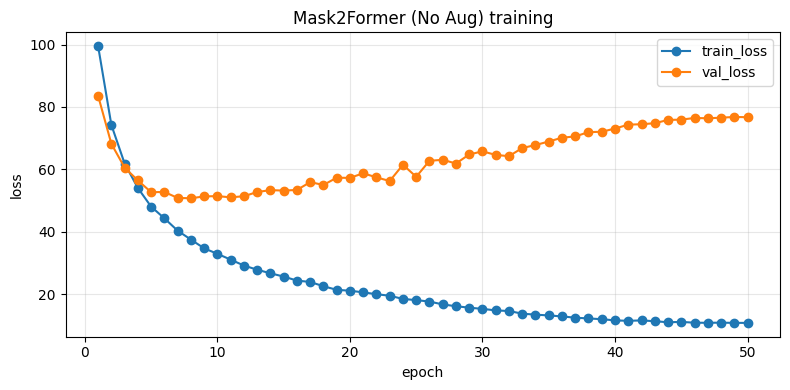

,epoch,train_loss,val_loss,lr,lr_backbone
45,46,10.8393,76.4787,0.0,0.0
46,47,10.8077,76.3816,0.0,0.0
47,48,10.8526,76.5719,0.0,0.0
48,49,10.7799,76.8018,0.0,0.0
49,50,10.7848,76.7270,0.0,0.0


In [14]:
plot_m2f_history(hist_no_aug, "Mask2Former (No Aug) training")

Loading weights:   0%|          | 0/556 [00:00<?, ?it/s]

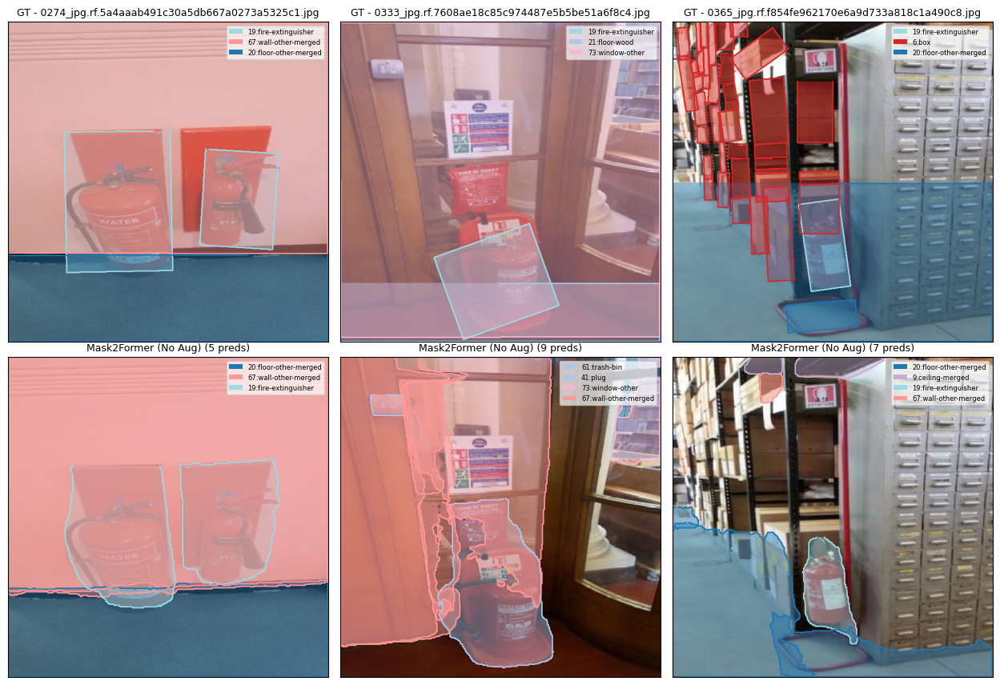

In [15]:
preview_m2f_run(M2F_DIR_NO_AUG, "Mask2Former (No Aug)")

## 7. Experiment 2 - Mask2Former (Augmentation 1)

In [16]:
hist_aug_1, M2F_DIR_AUG_1 = train_mask2former_experiment("aug_1", "Mask2Former (Aug 1)")

Loading weights:   0%|          | 0/554 [00:00<?, ?it/s]

[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-tiny-coco-instance
Key                                                                                                                                | Status     |                                                                                         
-----------------------------------------------------------------------------------------------------------------------------------+------------+-----------------------------------------------------------------------------------------
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0, 1, 2, 3, 4, 5}.attention.self.relative_position_index | UNEXPECTED |                                                                                         
model.pixel_level_module.encoder.swin.layernorm.bias                                                                               | MISSING    |                                    

[Mask2Former (Aug 1)] Mask2Former params: 47.4 M
[Mask2Former (Aug 1)] num_labels: 74 | queries: 100
[Mask2Former (Aug 1)] sample batch: {'pixel_values': (4, 3, 640, 640), 'mask_labels': 'list[4] of (8, 640, 640)', 'class_labels': 'list[4] of (8,)'}


Mask2Former (Aug 1) 1/50:   0%|          | 0/100 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

epoch 01 | train 99.479 | val 83.015 | lr 5.60e-05 (bb 5.60e-06)


... (104 outputs left out)

Mask2Former (Aug 1) 50/50:   0%|          | 0/100 [00:00<?, ?it/s]

epoch 50 | train 15.328 | val 62.528 | lr 0.00e+00 (bb 0.00e+00)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

saved: /content/outputs_augmentation/mask2former_aug_1


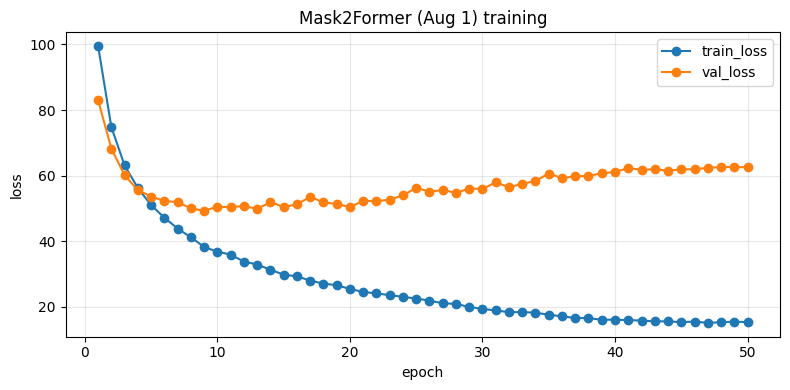

,epoch,train_loss,val_loss,lr,lr_backbone
45,46,15.5106,61.9153,0.0,0.0
46,47,15.0887,62.3921,0.0,0.0
47,48,15.3029,62.5888,0.0,0.0
48,49,15.4679,62.6606,0.0,0.0
49,50,15.3285,62.5281,0.0,0.0


In [17]:
plot_m2f_history(hist_aug_1, "Mask2Former (Aug 1) training")

Loading weights:   0%|          | 0/556 [00:00<?, ?it/s]

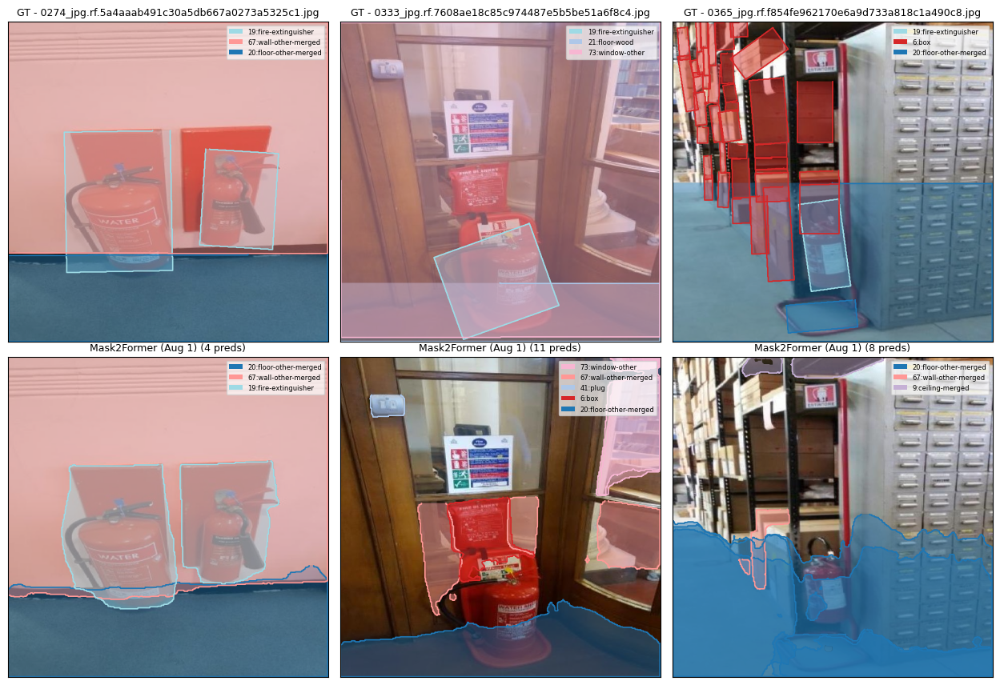

In [18]:
preview_m2f_run(M2F_DIR_AUG_1, "Mask2Former (Aug 1)")

## 8. Experiment 3 - Mask2Former (Augmentation 2)

In [19]:
hist_aug_2, M2F_DIR_AUG_2 = train_mask2former_experiment("aug_2", "Mask2Former (Aug 2)")

Loading weights:   0%|          | 0/554 [00:00<?, ?it/s]

[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-tiny-coco-instance
Key                                                                                                                                | Status     |                                                                                         
-----------------------------------------------------------------------------------------------------------------------------------+------------+-----------------------------------------------------------------------------------------
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0, 1, 2, 3, 4, 5}.attention.self.relative_position_index | UNEXPECTED |                                                                                         
model.pixel_level_module.encoder.swin.layernorm.bias                                                                               | MISSING    |                                    

[Mask2Former (Aug 2)] Mask2Former params: 47.4 M
[Mask2Former (Aug 2)] num_labels: 74 | queries: 100
[Mask2Former (Aug 2)] sample batch: {'pixel_values': (4, 3, 640, 640), 'mask_labels': 'list[4] of (8, 640, 640)', 'class_labels': 'list[4] of (8,)'}


Mask2Former (Aug 2) 1/50:   0%|          | 0/100 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

epoch 01 | train 101.707 | val 85.276 | lr 5.60e-05 (bb 5.60e-06)


... (112 outputs left out)

Mask2Former (Aug 2) 50/50:   0%|          | 0/100 [00:00<?, ?it/s]

epoch 50 | train 28.001 | val 48.691 | lr 0.00e+00 (bb 0.00e+00)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

saved: /content/outputs_augmentation/mask2former_aug_2


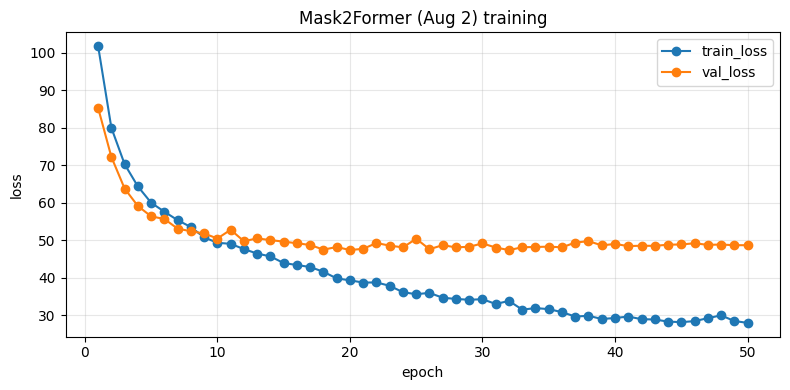

,epoch,train_loss,val_loss,lr,lr_backbone
45,46,28.4696,49.2096,0.0,0.0
46,47,29.2545,48.7857,0.0,0.0
47,48,30.0065,48.8715,0.0,0.0
48,49,28.5072,48.6925,0.0,0.0
49,50,28.0005,48.6907,0.0,0.0


In [20]:
plot_m2f_history(hist_aug_2, "Mask2Former (Aug 2) training")

Loading weights:   0%|          | 0/556 [00:00<?, ?it/s]

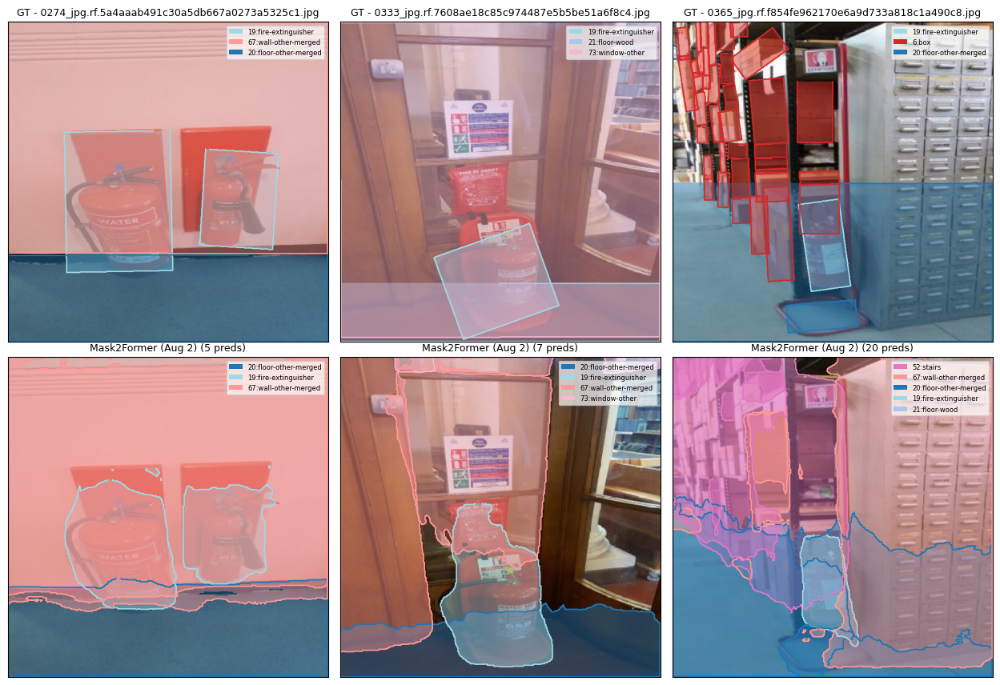

In [21]:
preview_m2f_run(M2F_DIR_AUG_2, "Mask2Former (Aug 2)")

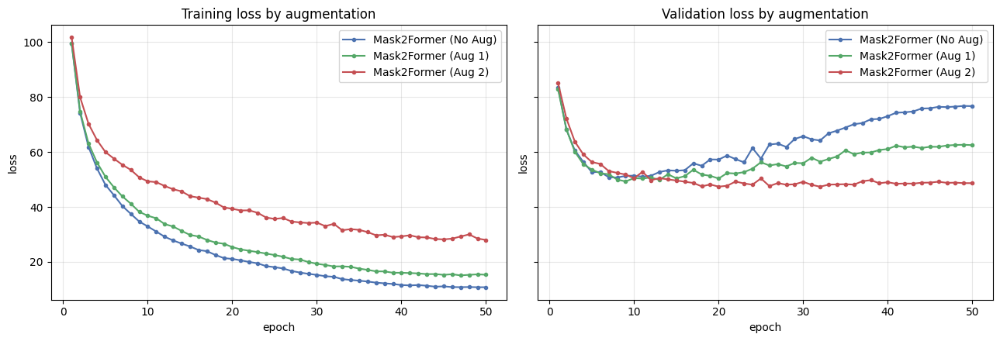

In [22]:
# Combined training & validation loss curves across all 3 augmentation strategies
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
colors = {"no_aug": "#4C72B0", "aug_1": "#55A868", "aug_2": "#C44E52"}

for exp in AUG_EXPERIMENTS:
    key = exp["key"]
    hist = M2F_HISTORIES.get(key)
    if hist is None and (M2F_DIRS[key] / "history.json").is_file():
        hist = json.loads((M2F_DIRS[key] / "history.json").read_text())
    if not hist:
        continue
    df = pd.DataFrame(hist)
    axes[0].plot(df["epoch"], df["train_loss"], marker="o", ms=3, color=colors[key], label=exp["label"])
    axes[1].plot(df["epoch"], df["val_loss"], marker="o", ms=3, color=colors[key], label=exp["label"])

axes[0].set_title("Training loss by augmentation")
axes[1].set_title("Validation loss by augmentation")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.set_ylabel("loss")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "loss_comparison.png", dpi=150)
plt.show()

# Free validation DataLoader workers before full COCO evaluation
for _v in ("hf_val_loader", "hf_val_ds"):
    if _v in globals():
        del globals()[_v]
gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

## 9. Unified evaluation: mask mAP with pycocotools

In [23]:
coco_gt = COCO(str(EVAL_COCO))
NAME2ID = {v["file_name"]: k for k, v in coco_gt.imgs.items()}


def encode_rle(mask):
    return mask_utils.encode(np.asfortranarray((np.asarray(mask) > 0).astype(np.uint8)))


def to_coco_results(preds, image_paths):
    results = []
    for p, d in zip(image_paths, preds):
        for m, l, s in zip(d["masks"], d["labels"], d["scores"]):
            if m.sum() == 0:
                continue
            results.append({"image_id": NAME2ID[p.name], "category_id": int(l) + 1,
                            "segmentation": encode_rle(m), "score": float(s)})
    return results


def eval_segm(results, name):
    if not results:
        return {"experiment": name}
    dt = coco_gt.loadRes(results)
    e = COCOeval(coco_gt, dt, "segm")
    e.params.imgIds = sorted(coco_gt.getImgIds())
    e.evaluate()
    e.accumulate()
    with contextlib.redirect_stdout(io.StringIO()):
        e.summarize()
    s = e.stats
    return {"experiment": name, "mAP@50-95": s[0], "mAP@50": s[1], "mAP@75": s[2],
            "mAP_small": s[3], "mAP_medium": s[4], "mAP_large": s[5], "AR@100": s[8]}


# --- predictions across all 3 Mask2Former augmentation runs -----------------
COCO_RESULTS = {}
(OUT_DIR / "preds").mkdir(exist_ok=True)

for exp in AUG_EXPERIMENTS:
    key = exp["key"]
    t0 = time.time()
    model_eval = load_best_mask2former(M2F_DIRS[key])
    preds = mask2former_predict(model_eval, m2f_processor, EVAL_IMAGES, score_thr=0.0, max_det=100)
    model_eval.cpu()
    del model_eval
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    res = to_coco_results(preds, EVAL_IMAGES)
    COCO_RESULTS[key] = res
    print(f"{key:<8s}: {len(res)} detections, {time.time() - t0:.1f}s")
    (OUT_DIR / "preds" / f"{key}.json").write_text(
        json.dumps(res, default=lambda o: o.decode() if isinstance(o, bytes) else None)
    )

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


Loading weights:   0%|          | 0/556 [00:00<?, ?it/s]

no_aug  : 16429 detections, 49.2s


Loading weights:   0%|          | 0/556 [00:00<?, ?it/s]

aug_1   : 16318 detections, 48.6s


Loading weights:   0%|          | 0/556 [00:00<?, ?it/s]

aug_2   : 16158 detections, 46.8s


In [24]:
rows = [
    eval_segm(COCO_RESULTS[exp["key"]], exp["label"])
    for exp in AUG_EXPERIMENTS
]

METRICS = pd.DataFrame(rows).set_index("experiment")
pd.set_option("display.float_format", lambda v: f"{v:.3f}")
METRICS.to_csv(OUT_DIR / "metrics_segm.csv")
METRICS

Loading and preparing results...
DONE (t=0.34s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=1.63s).
Accumulating evaluation results...
DONE (t=0.50s).
Loading and preparing results...
DONE (t=0.31s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=1.58s).
Accumulating evaluation results...
DONE (t=0.46s).
Loading and preparing results...
DONE (t=0.28s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=1.85s).
Accumulating evaluation results...
DONE (t=0.48s).


,mAP@50-95,mAP@50,mAP@75,mAP_small,mAP_medium,mAP_large,AR@100
experiment,,,,,,,
Mask2Former (No Aug),0.154,0.297,0.131,0.052,0.119,0.212,0.281
Mask2Former (Aug 1),0.154,0.291,0.140,0.039,0.115,0.217,0.260
Mask2Former (Aug 2),0.211,0.372,0.200,0.054,0.134,0.283,0.357


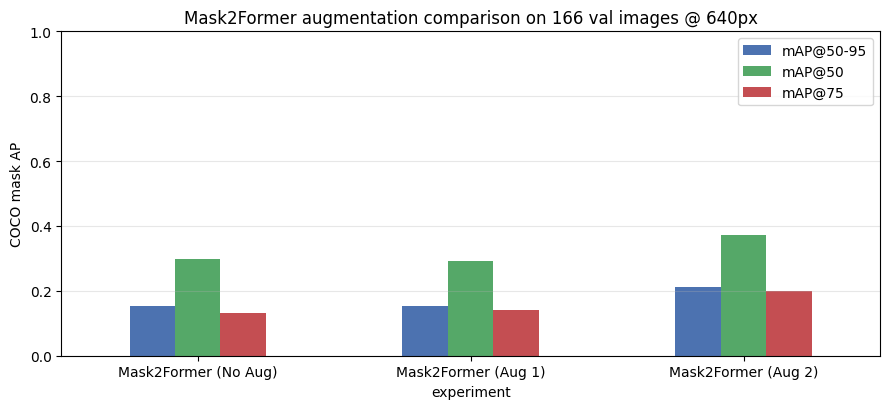

In [25]:
ax = METRICS[["mAP@50-95", "mAP@50", "mAP@75"]].plot.bar(
    figsize=(9, 4.2), rot=0, color=["#4C72B0", "#55A868", "#C44E52"]
)
ax.set_ylabel("COCO mask AP")
ax.set_ylim(0, 1)
ax.set_title(f"Mask2Former augmentation comparison on {len(EVAL_IMAGES)} {EVAL_SPLIT} images @ {IMG_SIZE}px")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR / "metrics_segm.png", dpi=150)
plt.show()

## 10. Side-by-side qualitative comparison

Same four validation images, same colours, one row per augmentation strategy.

Loading weights:   0%|          | 0/556 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/556 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/556 [00:00<?, ?it/s]

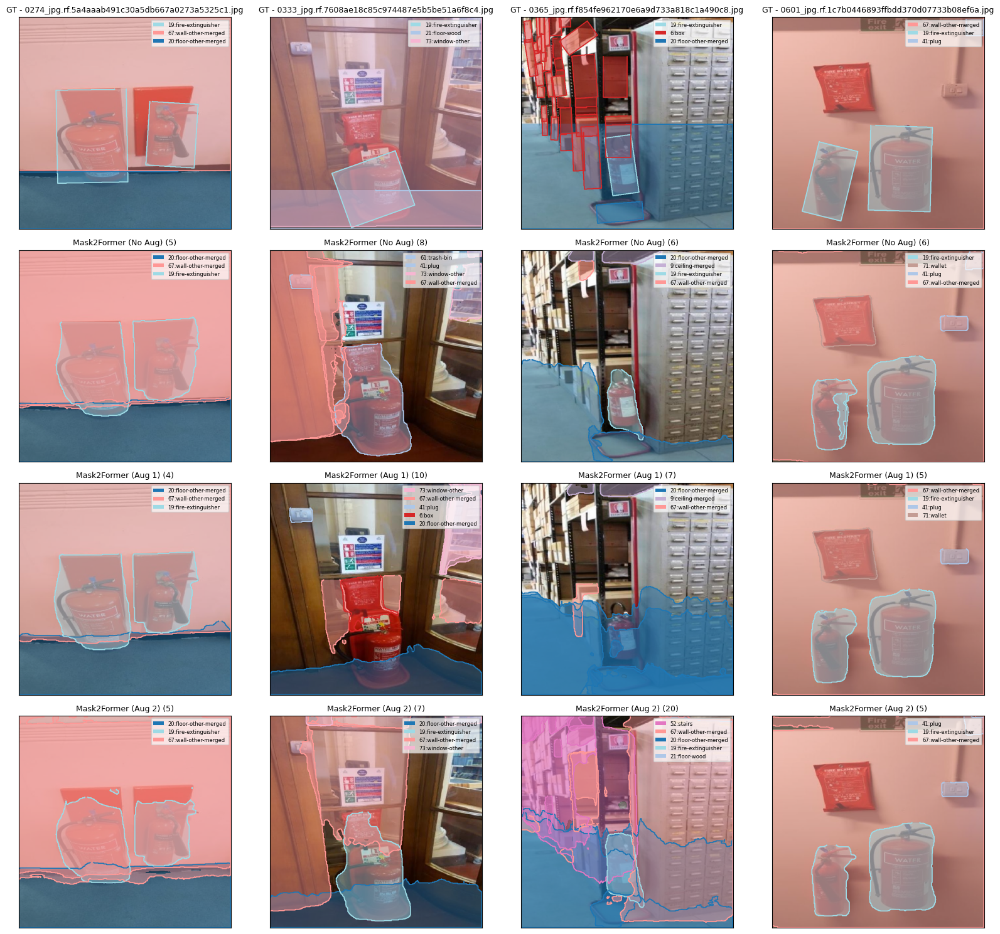

In [26]:
comp_imgs = VAL_IMAGES[:4]
comp_preds = {}

for exp in AUG_EXPERIMENTS:
    key = exp["key"]
    model_eval = load_best_mask2former(M2F_DIRS[key])
    comp_preds[exp["label"]] = mask2former_predict(
        model_eval, m2f_processor, comp_imgs, score_thr=0.5, max_det=20
    )
    model_eval.cpu()
    del model_eval
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

fig, axes = plt.subplots(1 + len(AUG_EXPERIMENTS), len(comp_imgs), figsize=(4.1 * len(comp_imgs), 15))
for j, p in enumerate(comp_imgs):
    img = load_rgb(p)
    gt_m, gt_l = masks_from_instances(read_labels(VAL_LABELS / f"{p.stem}.txt", IMG_SIZE, IMG_SIZE))
    draw_instances(axes[0, j], img, gt_m, gt_l, title=f"GT - {p.name}")
    for r, (name, preds) in enumerate(comp_preds.items(), start=1):
        d = preds[j]
        draw_instances(axes[r, j], img, d["masks"], d["labels"],
                       title=f"{name} ({len(d['masks'])})")
for ax in axes.ravel():
    if not ax.images:
        ax.axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR / "comparison.png", dpi=140)
plt.show()

In [27]:
print("Summary\n" + "=" * 64)
for name, row in METRICS.iterrows():
    print(f"{name:<24s} mAP@50-95={row['mAP@50-95']:.3f}   mAP@50={row['mAP@50']:.3f}   mAP@75={row['mAP@75']:.3f}")
print("=" * 64)
best = METRICS["mAP@50-95"].idxmax()
print(f"Best mask AP@50-95: {best}")
print("\nOutputs:")
for p in [M2F_DIRS["no_aug"], M2F_DIRS["aug_1"], M2F_DIRS["aug_2"], OUT_DIR / "metrics_segm.csv"]:
    print(f"  {'OK ' if Path(p).exists() else 'MISSING'} {p}")

Summary
Mask2Former (No Aug)     mAP@50-95=0.154   mAP@50=0.297   mAP@75=0.131
Mask2Former (Aug 1)      mAP@50-95=0.154   mAP@50=0.291   mAP@75=0.140
Mask2Former (Aug 2)      mAP@50-95=0.211   mAP@50=0.372   mAP@75=0.200
Best mask AP@50-95: Mask2Former (Aug 2)

Outputs:
  OK  /content/outputs_augmentation/mask2former_no_aug
  OK  /content/outputs_augmentation/mask2former_aug_1
  OK  /content/outputs_augmentation/mask2former_aug_2
  OK  /content/outputs_augmentation/metrics_segm.csv
